In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning')

import neuron
from neuron import h
from plot_utils_other import assign_color
import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_2025_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/'
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'


import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_cells_dev/utils')
from cell_builder_utils import _get_dends, _get_pyr_soma, Cell, l2_params
from l5_mechs_utils import Ih_condu_hay, linear_gbar
from l23_mechs_utils import Mechs

from functools import partial
import os
from hnn_core.viz import plot_cell_morphology

# The number of cores may need modifying depending on your current machine.
n_procs = 10
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'

# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels

In [2]:
# L2/3

model_params = {'soma': {'NaTs2_t_32d': 20_400e-4*1.2,
                                'SKv3_1': 6_930e-4*1.,
                                'Nap_Et2': 1e-4/2*0,
                                'Ca_HVA': 9.92e-04,
                                'Ca_LVAst': 34.3e-4,
                                
                                'SK_E2': 3.e-05,
                                'pas': 1.0 / 15000,
                                'Ih': 0.000080/2,
                                'Im': 8e-3*0.05,
                                'CaDynamics_E2': {'decay': 90, 'gamma': 0.00053300}},
                        'basal': {'NaTs2_t_32d': 0.008009,#partial(linear_gbar,0.008009/2,0,255),
                                  'SKv3_1': 0.000513,#partial(linear_gbar,0,6_930e-4*0.1,255),
                                  'Ih': 0.00008/2,
                                  'pas':  1.0 / 13000.0},
                        'dend': {'NaTa_t_32d': 0.008*0.0001,
                                'SKv3_1': 0.003*3,
                                'Ca_HVA': partial(linear_gbar, 0.00001, 0.002, 200, hotzone=[200, 400], hotzone_factor=4),#0.0013791999171895088/10,
                                'Ca_LVAst': partial(linear_gbar, 0.0000001, 0.001, 200, hotzone=[200, 400], hotzone_factor=4),
                                'pas': 1.0 /9000,
                                'SK_E2': partial(linear_gbar, 3.e-06, 3.e-03, 200, hotzone=[200, 400], hotzone_factor=10), #3.547577318022417e-05,
                                'Ih': partial(Ih_condu_hay, 0.000080),
                                'Im': 0.0009*0.0001,
                                'CaDynamics_E2': {'decay': 70, 'gamma': 0.00053300*2.5}},
                        'e_pas': -75}



v_init = {'soma': -73.91534035708573,
        'basal_1': -73.93352687563383,
        'basal_2': -73.98646383934111,
        'basal_3': -73.98646383934111,
        'apical_oblique': -73.91421209292815,
        'apical_trunk': -73.88877758950657,
        'apical_1': -73.64560269252748,
        'apical_tuft': -73.27793049058045}

# get paramaters
section_params, end_pts, cell_tree = l2_params()

# build sections
section_names = list(end_pts.keys())


sections = _get_dends(section_params, 'L2Pyr', section_names, end_pts, v_init=v_init)
sections['soma'] = _get_pyr_soma(section_params, 'L2Pyr', end_pts['soma'], v_init=v_init['soma'])

mech_class = Mechs(pth_mod)

l2pyr= Cell(sections, cell_tree, cell_type = 'L2_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 50
stim.amp = 3

t = h.Vector().record(h._ref_t)

soma_voltg = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)
apical_voltg = h.Vector().record(l2pyr._nrn_sections['apical_tuft'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(100)

v_np = soma_voltg.to_python()
a_np = apical_voltg.to_python()

distance_apical = []
gbar_Ih_apical = []
gbar_Ca_HVA_apical = []
gbar_Ca_LVA_apical = []
gbar_SK_E2_apical = []

apical_sections=['apical_trunk', 'apical_1', 'apical_tuft']
h.distance(sec = l2pyr._nrn_sections['soma'])
for section in apical_sections:
    for seg in l2pyr._nrn_sections[section]:
        distance_apical.append(h.distance(seg.x, sec=seg.sec))
        gbar_Ih_apical.append(seg.gbar_Ih)
        gbar_Ca_HVA_apical.append(seg.gbar_Ca_HVA)
        gbar_Ca_LVA_apical.append(seg.gbar_Ca_LVAst)
        gbar_SK_E2_apical.append(seg.gbar_SK_E2)

In [3]:
h('forall delete_section()')
# HNN
net = duecker_2025_ET_model(mesh_shape=(1,1))
net.clear_connectivity()
net.add_tonic_bias(cell_type='L2_pyramidal', section='soma', bias_name='clamp', amplitude=3, t0=20, tstop = 70)
dpl = simulate_dipole(net, tstop=100, bsl_cor='calcium', record_vsec='all', record_ca='all', record_isec='all')

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying calcium model baseline correction


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:76: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn(


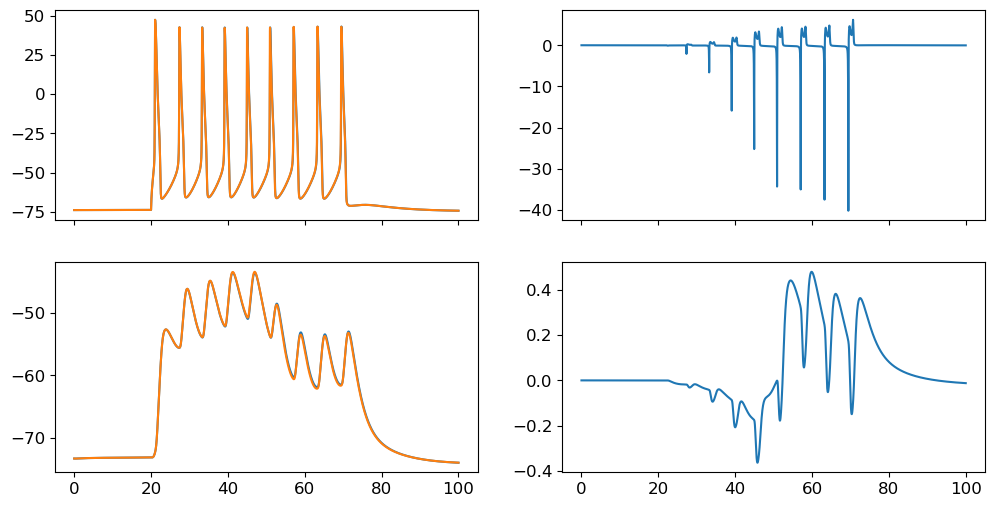

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
ax[0,0].plot(t, v_np, label='NEURON')
ax[0,0].plot(net.cell_response.times, net.cell_response.vsec[0][1]['soma'], label='HNN')
ax[0,1].plot(t, np.array(v_np)-np.array(net.cell_response.vsec[0][1]['soma']), label='Difference')
#ax[0,1].set_xlim((15, 35))
ax[1,0].plot(t, a_np, label='NEURON')
ax[1,0].plot(net.cell_response.times, net.cell_response.vsec[0][1]['apical_tuft'], label='HNN')
ax[1,1].plot(t, np.array(a_np)-np.array(net.cell_response.vsec[0][1]['apical_tuft']), label='Difference')

In [5]:
net.cell_types['L2_pyramidal']['cell_object'].sections['soma'].L

22.1

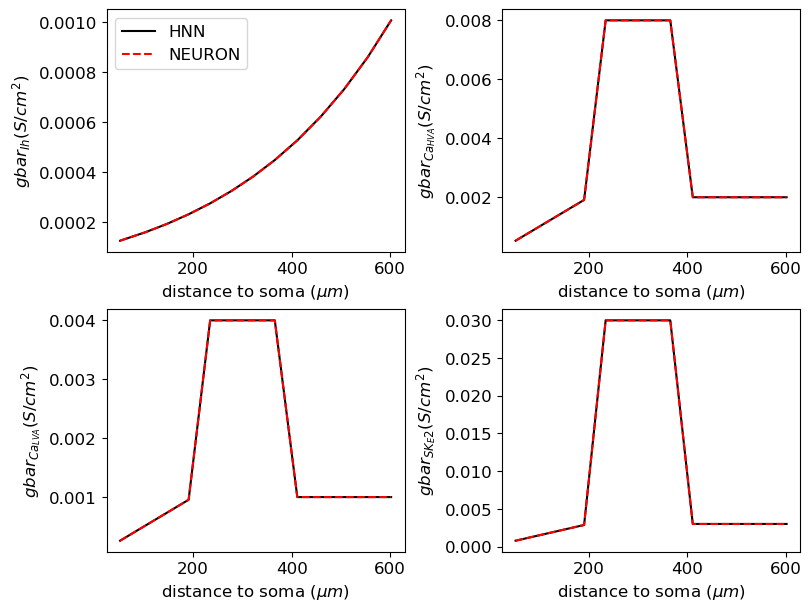

In [6]:


L = net.cell_types['L2_pyramidal']['cell_object'].sections['soma'].L
distance_HNN = []
Ih = []
CHVA = []
CLVA = []

apical_sections=['apical_trunk', 'apical_1', 'apical_tuft']
for section in apical_sections:
    for s, seg in enumerate(net.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][0]):
        distance_HNN.append(float(L+net.cell_types['L2_pyramidal']['cell_object'].sections[section].L*seg))
        Ih.append(net.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ih']['gbar_Ih'][1][s])
        CHVA.append(net.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1][s])
        CLVA.append(net.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1][s])

    L += net.cell_types['L2_pyramidal']['cell_object'].sections[section].L


fig, ax = plt.subplots(2,2, figsize=(8, 6), constrained_layout=True)
ax =ax.flatten()
ax[0].plot(distance_HNN, Ih, color='k', label='HNN')
ax[0].plot(distance_apical, gbar_Ih_apical, color='r', linestyle='--', label='NEURON')
ax[0].set_ylabel('$gbar_{Ih} (S/cm^2)$')
ax[0].set_xlabel('distance to soma ($\mu m$)')
ax[1].plot(distance_HNN, CHVA, color='k', label='HNN')
ax[1].plot(distance_apical, gbar_Ca_HVA_apical, color='r', linestyle='--', label='NEURON')
ax[1].set_ylabel('$gbar_{Ca_{HVA}} (S/cm^2)$')
ax[1].set_xlabel('distance to soma ($\mu m$)')
ax[2].plot(distance_HNN, CLVA, color='k', label='HNN')
ax[2].plot(distance_apical, gbar_Ca_LVA_apical, color='r', linestyle='--', label='NEURON')
ax[2].set_ylabel('$gbar_{Ca_{LVA}} (S/cm^2)$')
ax[2].set_xlabel('distance to soma ($\mu m$)')

ax[3].plot(distance_HNN, gbar_SK_E2_apical, color='k', label='HNN')
ax[3].plot(distance_apical, gbar_SK_E2_apical, color='r', linestyle='--', label='NEURON')
ax[3].set_ylabel('$gbar_{SK_E2} (S/cm^2)$')
ax[3].set_xlabel('distance to soma ($\mu m$)')
ax[0].legend()

fig.savefig(op.join(pathfig, 'fig_conductance_L2.pdf'))

In [7]:
np.array(distance_apical) - np.array(distance_HNN)

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 5.68434189e-14, 5.68434189e-14, 5.68434189e-14,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00])